<a href="https://colab.research.google.com/github/NumericAnalysis/Numeric_Analysis_restricted-access/blob/main/runcodes3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
# Topcu atisi
from numpy import *
from pylab import *
def rk4m(x,y,h,n):
    X = []
    Y = []
    X.append(x)
    Y.append(y)
    for i in range(n):
        k0 = f(x,y)
        k1 = f(x + h/2.0, y + (h/2)*k0)
        k2 = f(x + h/2.0, y + (h/2)*k1)
        k3 = f(x + h, y + h*k2)
        y=y+(h/6)*(k0 + 2.0*k1 + 2.0*k2 + k3)    
        x = x + h
        X.append(x)
        Y.append(y)
    return X,Y
def f(x,y):
    f = zeros((2))
    f[0] = y[1]
    f[1] = -y[0]-1.0*(y[0]**2-1.0)*y[1]
    return f
xa=0.0;xb=1.0;ya=1.0;yb=0.36787944
n=100
h=(xb-xa)/n
tol=1.0e-6
dene1=1.0
dd=0.01
dene2=dene1+dd
x0=xa
for i in range(10):
    y0=array([ya,dene1])
    X,Y = rk4m(x0,y0,h,n)
    hata1=Y[n][0]-yb
    y0=array([ya,dene2])
    X,Y = rk4m(x0,y0,h,n)
    hata2=Y[n][0]-yb
    dhata=hata2-hata1
    if abs(dhata)<tol:
        print("Cozum bulundu")
        break
    else:
        gecici=dene2-hata2*(dene2-dene1)/dhata
        dene1=dene2
        dene2=gecici
y1=[y1 for y1,y2 in Y]
m = len(Y)
y_tam=zeros(m,float)
for i in range(m):
    y_tam[i]=exp(-X[i]**2)
    print ("%10.3f"% X[i], "%12.3f"% y1[i], "%12.3f"% y_tam[i])
plot(X,y1,"k",linewidth=5)
plot(X,y_tam,"r--",linewidth=4)
show()


In [ ]:
# LAplace denklemi
from numpy import *
from pylab import *
def rk4m(x,y,h,n):
    X = []
    Y = []
    X.append(x)
    Y.append(y)
    for i in range(n):
        k0 = f(x,y)
        k1 = f(x + h/2.0, y + (h/2)*k0)
        k2 = f(x + h/2.0, y + (h/2)*k1)
        k3 = f(x + h, y + h*k2)
        y=y+(h/6)*(k0 + 2.0*k1 + 2.0*k2 + k3)    
        x = x + h
        X.append(x)
        Y.append(y)
    return X,Y
def f(x,y):
    f = zeros((2))
    f[0] = y[1]
    f[1] = -2*y[1]/x
    return f
ra=1.0;rb=2.0;va=100.0;vb=0.0
n=100
h=(rb-ra)/n
tol=1.0e-6
dene1=1.0
dd=0.01
dene2=dene1+dd
r0=ra
for i in range(10):
    v0=array([va,dene1])
    R,V = rk4m(r0,v0,h,n)
    hata1=V[n][0]-vb
    v0=array([va,dene2])
    R,V = rk4m(r0,v0,h,n)
    hata2=V[n][0]-vb
    dhata=hata2-hata1
    if abs(dhata)<tol:
        print("Cozum bulundu")
        break
    else:
        gecici=dene2-hata2*(dene2-dene1)/dhata
        dene1=dene2
        dene2=gecici
v=[v1 for v1,v2 in V]
m = len(V)
v_tam=zeros(m,float)
for i in range(m):
    v_tam[i]=(rb-R[i])*ra*va/((rb-ra)*R[i])
    print ("%10.3f"% R[i], "%12.3f"% v[i], "%12.3f"% v_tam[i])
plot(R,v,"kx",ms=10)
plot(R,v_tam,"r--",linewidth=3)
show()


In [ ]:
# Telde kararli dalgalar
from numpy import *
from pylab import *
def rk4m(x,y,h,n):
    X = []
    Y = []
    X.append(x)
    Y.append(y)
    for i in range(n):
        k0 = f(x,y)
        k1 = f(x + h/2.0, y + (h/2)*k0)
        k2 = f(x + h/2.0, y + (h/2)*k1)
        k3 = f(x + h, y + h*k2)
        y=y+(h/6)*(k0 + 2.0*k1 + 2.0*k2 + k3)    
        x = x + h
        X.append(x)
        Y.append(y)
    return X,Y
def f(x,y):
    global ozdeger
    f = zeros((2))
    f[0] = y[1]
    f[1] = -ozdeger**2*y[0]
    return f
n=100
h=1.0/n
tol=1.0e-8
x0=0.0
y0=array([0.0,0.1])
ddilk=0.5
dd=ddilk
ozeski=ddilk
ozdeger=ozeski
X,Y = rk4m(x0,y0,h,n)
yeski=Y[n][0]
nsayi=0
m=len(Y)
while nsayi<6:
    ozyeni=ozeski+dd
    ozdeger=ozyeni
    X,Y = rk4m(x0,y0,h,n)
    yyeni=Y[n][0]
    if yyeni*yeski>0.0:
        ozeski=ozyeni
        yeski=yyeni
    else:
        dd=dd/2.0
        if dd<tol:
            nsayi=nsayi+1
            print ("n = ", nsayi, "kn = " "%.10f" % ozdeger, "kn/pi=" "%.8f" % float(ozdeger/pi))
            if nsayi<5:
                y1=[y1 for y1,y2 in Y]
                plot(X,y1)
            dd=ddilk
            ozeski=ozyeni+dd
            yeski=yyeni
xlim(0.0,1.0)
show()


In [ ]:
# Kuantum salinici
from numpy import *
from pylab import *
def rk4m(x,y,h,n):
    X = []
    Y = []
    X.append(x)
    Y.append(y)
    for i in range(n):
        k0 = f(x,y)
        k1 = f(x + h/2.0, y + (h/2)*k0)
        k2 = f(x + h/2.0, y + (h/2)*k1)
        k3 = f(x + h, y + h*k2)
        y=y+(h/6)*(k0 + 2.0*k1 + 2.0*k2 + k3)    
        x = x + h
        X.append(x)
        Y.append(y)
    return X,Y
def f(x,y):
    global ozdeger
    f = zeros((2))
    f[0] = y[1]
    f[1] = (x**2-ozdeger)*y[0]
    return f
iparite = eval(raw_input("Tek durumlar icin 1, cift durumlar icin 2 girin ="))
n=200
h=0.03
tol=1.0e-9
x0=0.0
if iparite==1:
    print("Tek durumlar :")
    y0=array([0.0,1.0])
else:
    print("Cift durumlar :")
    y0=array([1.0,0.0])
ddilk=0.5
dd=ddilk
ozeski=ddilk
ozdeger=ozeski
X,Y = rk4m(x0,y0,h,n)
yeski=Y[n][0]
nsayi=0
m=len(Y)
while nsayi<6:
    ozyeni=ozeski+dd
    ozdeger=ozyeni
    X,Y = rk4m(x0,y0,h,n)
    yyeni=Y[n][0]
    if yyeni*yeski>0.0:
        ozeski=ozyeni
        yeski=yyeni
    else:
        dd=dd/2.0
        if dd<tol:
            nsayi=nsayi+1
            nozdeger=2*nsayi-iparite
            print ("n = ", nozdeger, "ozdeger = " "%.8f" % ozdeger)
            if nsayi<4:
                y1=[y1 for y1,y2 in Y]
                nn=len(X)
                yd=zeros(2*nn-1)
                xd=zeros(2*nn-1)
                for i in range(nn-1):
                        xd[i]=-X[nn-1-i]
                        xd[i+nn]=X[i+1]
                        yd[i]=(2*iparite-3)*y1[nn-1-i]
                        yd[i+nn]=y1[i+1]
                        yd[nn-1]=y1[0]
                plot(xd,yd)
            dd=ddilk
            ozeski=ozyeni+dd
            yeski=yyeni
xlim(-5.0,5.0)
show()


In [ ]:
# Hidrojen
from numpy import *
from pylab import *
def rk4m(x,y,h,n):
    X = []
    Y = []
    X.append(x)
    Y.append(y)
    for i in range(n):
        k0 = f(x,y)
        k1 = f(x + h/2.0, y + (h/2)*k0)
        k2 = f(x + h/2.0, y + (h/2)*k1)
        k3 = f(x + h, y + h*k2)
        y=y+(h/6)*(k0 + 2.0*k1 + 2.0*k2 + k3)    
        x = x + h
        X.append(x)
        Y.append(y)
    return X,Y
def f(x,y):
    global L,ozdeger
    f = zeros((2))
    f[0] = y[1]
    if x==0:
        f[1]=0
    else:
        f[1] = (0.25+(L*(L+1)/x-ozdeger)/x)*y[0]
    return f
L = eval(raw_input("L degerini girin (0,1,2,3,4) ="))
n=200
h=0.1
tol=1.0e-10
x0=0.0
y0=array([0.0,0.1])
ddilk=0.5
dd=ddilk
ozeski=ddilk
ozdeger=ozeski
nsayi=0
X,Y = rk4m(x0,y0,h,n)
yeski=Y[n][0]
m=len(Y)
while nsayi<3:
    ozyeni=ozeski+dd
    ozdeger=ozyeni
    X,Y = rk4m(x0,y0,h,n)
    yyeni=Y[n][0]
    if yyeni*yeski>0.0:
        ozeski=ozyeni
        yeski=yyeni
    else:
        dd=dd/2.0
        if dd<tol:
            nsayi=nsayi+1
            print ("n = ", nsayi, "ozdeger = " "%.8f" % ozdeger)
            if nsayi<4:
                y1=[y1 for y1,y2 in Y]
                for i in range(len(y1)):
                    if i==0:
                        y1[0]=0
                    else:
                        y1[i]=(y1[i]/X[i])**2
                plot(X,y1)
            dd=ddilk
            ozeski=ozyeni+dd
            yeski=yyeni
show()


In [ ]:
def gausel(a,b,tol):
    n = len(b)
# i.ci sutundaki maksimum elemani bul
    s = zeros((n),dtype=float)
    for i in range(n):
        s[i] = max(abs(a[i,:]))
    for k in range(n-1):
# a ve b nin satirlarini pivotla
        p = int(argmax(abs(a[k:n,k])/s[k:n])) + k
        if abs(a[p,k]) < tol: print('Matris tekil')
        if p != k:
            b[k,],b[p,] = copy(b[p,]),copy(b[k,])
            s[k,],s[p,] = copy(s[p,]),copy(s[k,])
            a[k,],a[p,] = copy(a[p,]),copy(a[k,])
# Pivotu sakla, a ve b sutun islemlerini yap
        for i in range(k+1,n):
            if a[i,k] != 0.0:
                cc = a[i,k]/a[k,k]
                a[i,k+1:n] = a[i,k+1:n] - cc*a[k,k+1:n]
                b[i] = b[i] - cc*b[k]
    if abs(a[n-1,n-1]) < tol: print('Matris tekil')
# Geri yerlestirme
    for k in range(n-1,-1,-1):
        b[k] = (b[k] - dot(a[k,k+1:n],b[k+1:n]))/a[k,k]
    return b


In [ ]:
#  Kirchoff
from numpy import *
def gausel(a,b,tol):
    n = len(b)
# i.ci sutundaki maksimum elemani bul
    s = zeros((n),dtype=float)
    for i in range(n):
        s[i] = max(abs(a[i,:]))
    for k in range(n-1):
# a ve b nin satirlarini pivotla
        p = int(argmax(abs(a[k:n,k])/s[k:n])) + k
        if abs(a[p,k]) < tol: print('Matris tekil')
        if p != k:
            b[k,],b[p,] = copy(b[p,]),copy(b[k,])
            s[k,],s[p,] = copy(s[p,]),copy(s[k,])
            a[k,],a[p,] = copy(a[p,]),copy(a[k,])
# Pivotu sakla, a ve b sutun islemlerini yap
        for i in range(k+1,n):
            if a[i,k] != 0.0:
                cc = a[i,k]/a[k,k]
                a[i,k+1:n] = a[i,k+1:n] - cc*a[k,k+1:n]
                b[i] = b[i] - cc*b[k]
    if abs(a[n-1,n-1]) < tol: print('Matris tekil')
# Geri yerlestirme
    for k in range(n-1,-1,-1):
        b[k] = (b[k] - dot(a[k,k+1:n],b[k+1:n]))/a[k,k]
    return b
a = array([[ 4.0,-1.0,-2.0],[-1.0,5.0,-2.0],[-2.0,-2.0,6.0]])
b = array([[0.0],[1.0], [5.0]])
tol=1.0e-6
x = gausel(a,b,tol)
for i in range(len(b[0])):
   print ("x",i+1,"=",x[:,i])



In [ ]:
def det(A):
    nr,nc = len(A),len(A[0])
# Eleme islemi
    sign=1
    for j in range(nr):
# Pivot satirini bul
        pivot_mag = abs(A[j][j])
        jpivot = j
        for ir in range(j+1, len(A)):
            this_mag = abs(A[ir][j])
            if this_mag > pivot_mag:
                jpivot = ir
                pivot_mag = this_mag
        if jpivot > j:
            A[j], A[jpivot] = A[jpivot], A[j]
            sign = -1 * sign
        pivot = A[j][j]
        if abs(pivot) < 1.0e-15:
            print "Matris tekil"
            return 0.0
# j.ci sutunun altindakileri ele
        for i in range(j+1,nr):
            alpha = -A[i][j]/pivot
            for jc in range(nc):
                A[i][jc]=A[i][jc]+alpha*A[j][jc]
# Kosegen elemanlardan determinanti kur
        d = sign
        for i in range(nr):
            d = d*A[i][i]
    return d


In [ ]:
# Determinant
import numpy
def det(A):
    nr,nc = len(A),len(A[0])
# Eleme islemi
    sign=1
    for j in range(nr):
# Pivot satirini bul
        pivot_mag = abs(A[j][j])
        jpivot = j
        for ir in range(j+1, len(A)):
            this_mag = abs(A[ir][j])
            if this_mag > pivot_mag:
                jpivot = ir
                pivot_mag = this_mag
        if jpivot > j:
            A[j], A[jpivot] = A[jpivot], A[j]
            sign = -1 * sign
        pivot = A[j][j]
        if abs(pivot) < 1.0e-15:
            print "Matris tekil"
            return 0.0
# j.ci sutunun altindakileri ele
        for i in range(j+1,nr):
            alpha = -A[i][j]/pivot
            for jc in range(nc):
                A[i][jc]=A[i][jc]+alpha*A[j][jc]
# Kosegen elemanlardan determinanti kur
        d = sign
        for i in range(nr):
            d = d*A[i][i]
    return d
A=[[1.,2.,-3.],[0.,2.,-2.],[1.,-2.,2.]]
print ("Determinant = ", det(A))


In [ ]:
#  Ters matris
from numpy import *
def gausel(a,b,tol):
    n = len(b)
# i.ci sutundaki maksimum elemani bul
    s = zeros((n),dtype=float)
    for i in range(n):
        s[i] = max(abs(a[i,:]))
    for k in range(0,n-1):
# a ve b nin satirlarini pivotla
        p = int(argmax(abs(a[k:n,k])/s[k:n])) + k
        if abs(a[p,k]) < tol: print('Matris tekil')
        if p != k:
            b[k,],b[p,] = copy(b[p,]),copy(b[k,])
            s[k,],s[p,] = copy(s[p,]),copy(s[k,])
            a[k,],a[p,] = copy(a[p,]),copy(a[k,])
# Pivotu sakla, a ve b sutun islemlerini yap
        for i in range(k+1,n):
            if a[i,k] != 0.0:
                cc = a[i,k]/a[k,k]
                a[i,k+1:n] = a[i,k+1:n] - cc*a[k,k+1:n]
                b[i] = b[i] - cc*b[k]
    if abs(a[n-1,n-1]) < tol: print('Matris tekil')
# Geri yerlestirme
    for k in range(n-1,-1,-1):
        b[k] = (b[k] - dot(a[k,k+1:n],b[k+1:n]))/a[k,k]
    return b
a = array([[1.,0.,-1.],[-2.,1.,0.],[1.,-1., 2.]])
b=array([[0.0]*3]*3)
for i in range(3):
    b[i][i]=1.0
tol=1.e-6
ainv = gausel(a,b,tol)
print (ainv)


In [ ]:
# Ozdeger ve ozvektorler
from numpy import *
def jacobi(a,tol): # Jacobi metodu
    n = len(a)
    maxRot = 5*(n**2)
    p = eye(n)*1.0
    for i in range(maxRot):
        aMax = 0.0
        for m in range(n-1):
            for j in range(m+1,n):
                if abs(a[m,j]) >= aMax:
                    aMax = abs(a[m,j])
                    k = m; l = j
        if aMax < tol: return diagonal(a),p
        aDiff = a[l,l] - a[k,k]
        if abs(a[k,l]) < abs(aDiff)*1.0e-36: \
           t = a[k,l]/aDiff
        else:
            phi = aDiff/(2.0*a[k,l])
            t = 1.0/(abs(phi) + sqrt(phi**2 + 1.0))
            if phi < 0.0: t = -t
        c = 1.0/sqrt(t**2 + 1.0); s = t*c
        tau = s/(1.0 + c)
        temp = a[k,l]
        a[k,l] = 0.0
        a[k,k] = a[k,k] - t*temp
        a[l,l] = a[l,l] + t*temp
        for i in range(k):
            temp = a[i,k]
            a[i,k] = temp - s*(a[i,l] + tau*temp)
            a[i,l] = a[i,l] + s*(temp - tau*a[i,l])
        for i in range(k+1,l):
            temp = a[k,i]
            a[k,i] = temp - s*(a[i,l] + tau*a[k,i])
            a[i,l] = a[i,l] + s*(temp - tau*a[i,l])
        for i in range(l+1,n):
            temp = a[k,i]
            a[k,i] = temp - s*(a[l,i] + tau*temp)
            a[l,i] = a[l,i] + s*(temp - tau*a[l,i])
        for i in range(n):
            temp = p[i,k]
            p[i,k] = temp - s*(p[i,l] + tau*p[i,k])
            p[i,l] = p[i,l] + s*(temp - tau*p[i,l])
    print "Cozum yok"

a = array([[ 3.0, 0.0,  -2.0],[0.0,  4.0,  0.0],[ -2.0,  0.0, 3.0]])
tol=1.0e-9
ozdeger,ozvektor= jacobi(a,tol)
print ("Ozdeger", " Ozvektor")
for i in range(len(ozvektor)):
    print (ozdeger[i],ozvektor[:,i])


In [ ]:
# Ozdeger ve ozvektorler
from numpy import *
a = array([[3.,0.,-2.],[0.,4.,0.],[-2.,0.,3.]])
tol=1.0e-9
ozdeger,ozvektor= jacobi(a,tol)
print "Ozdeger", " Ozvektor"
for i in range(len(ozvektor)):
    print (ozdeger[i],ozvektor[:,i])


In [ ]:
# Lagrange interpolasyon
def lagrange(x,xi,yi):
    n=len(xi)
    px = 0.0
    # sum over points
    for i in range(n):
        terim=1.0
        for j in range(n):
            if j!=i:
                terim=terim*(x-xi[j])/(xi[i]-xi[j])
        px = px + yi[i]*terim
    return px




In [ ]:
# Lagrange interpolasyon
def lagrange(x,xi,yi):
    n=len(xi)
    px = 0.0
    # sum over points
    for i in range(n):
        terim=1.0
        for j in range(n):
            if j!=i:
                terim=terim*(x-xi[j])/(xi[i]-xi[j])
        px = px + yi[i]*terim
    return px
xi=[200.,250.,273.,300.,350.,400.]
yi=[4.13,4.04,4.01,3.98,3.94,3.92]
x=320.
print("K = %.2f" % lagrange(x,xi,yi))




In [ ]:
def spline(xi,yi):
    a=yi[:]
    n=len(a)
    h = [0]*(n-1)
    alfa = [0]*(n-1)
    l = [0]*(n+1)
    u = [0]*(n)
    z = [0]*(n+1)
    b = [0]*n
    c = [0]*(n+1)
    d = [0]*(n)    
    for i in range(n-1):
        h[i] = xi[i+1]-xi[i]  
    for i in range(1, n-1):
        alfa[i]=(3./h[i])*(a[i+1]-a[i])-(3./h[i-1])*(a[i]-a[i-1])
    l[0] = 1      
    u[0] = 0      
    z[0] = 0
    for i in range(1, n-1):
        l[i] = 2*(xi[i+1] - xi[i-1]) - h[i-1]*u[i-1]
        u[i] = h[i]/l[i]
        z[i] = (alfa[i] - h[i-1]*z[i-1])/l[i]
    l[n] = 1
    z[n] = 0
    c[n] = 0
    for j in range(n-2, -1, -1):      
        c[j] = z[j] - u[j]*c[j+1]
        b[j] = (a[j+1]-a[j])/h[j]-h[j]*(c[j+1]+2*c[j])/3.
        d[j] = (c[j+1] - c[j])/(3*h[j]) 
    return a,b,c,d


In [ ]:
def splinex(xi,a,b,c,d,x):
    i=0
    while x>xi[i]:
        i=i+1
    i=i-1
    xd=x-xi[i]
    return a[i]+xd*(b[i]+xd*(c[i]+xd*d[i]))


In [ ]:
# Kubik serit
def spline(xi,yi):
    a=yi[:]
    n=len(a)
    h = [0]*(n-1)
    alfa = [0]*(n-1)
# l, u, z are used in the method for solving the linear system
    l = [0]*(n+1)
    u = [0]*(n)
    z = [0]*(n+1)
    # b, c, d will be the coefficients along with a.
    b = [0]*n
    c = [0]*(n+1)
    d = [0]*(n)    
    for i in range(n-1):
        h[i] = xi[i+1]-xi[i]  
    for i in range(1, n-1):
        alfa[i]=(3./h[i])*(a[i+1]-a[i])-(3./h[i-1])*(a[i]-a[i-1])
    l[0] = 1      
    u[0] = 0      
    z[0] = 0
    for i in range(1, n-1):
        l[i] = 2*(xi[i+1] - xi[i-1]) - h[i-1]*u[i-1]
        u[i] = h[i]/l[i]
        z[i] = (alfa[i] - h[i-1]*z[i-1])/l[i]
    l[n] = 1
    z[n] = 0
    c[n] = 0
    for j in range(n-2, -1, -1):      
        c[j] = z[j] - u[j]*c[j+1]
        b[j] = (a[j+1]-a[j])/h[j]-h[j]*(c[j+1]+2*c[j])/3.
        d[j] = (c[j+1] - c[j])/(3*h[j]) 
    return a,b,c,d
def splinex(xi,a,b,c,d,x):
    i=0
    while x>xi[i]:
        i=i+1
    i=i-1
    xd=x-xi[i]
    return a[i]+xd*(b[i]+xd*(c[i]+xd*d[i]))

xi=[0.,0.25,0.50,0.75,1.0,1.25,1.5,1.75,2.0]
yi=[0.0,0.276326,0.5205,0.711156,0.842701,\
    0.922900,0.966105,0.986672,0.995322]
a,b,c,d=spline(xi,yi)
x=1.1
print ("erf(",x,") = %.6f" % splinex(xi,a,b,c,d,x))

In [ ]:
def ekk(xData,yData,m):
    tol=1.0e-6
    a = zeros((m+1,m+1))
    b = zeros(m+1)
    s = zeros(2*m+1)
    for i in range(len(xData)):
        temp = yData[i]
        for j in range(m+1):
            b[j] = b[j] + temp
            temp = temp*xData[i]
        temp = 1.0
        for j in range(2*m+1):
            s[j] = s[j] + temp
            temp = temp*xData[i]
    for i in range(m+1):
        for j in range(m+1):
            a[i,j] = s[i+j]
    return gausel(a,b,tol)


In [ ]:
# En kucuk kareler    
from numpy import *
from pylab import *
def gausel(a,b,tol):
    n = len(b)
# i.ci sutundaki maksimum elemani bul
    s = zeros((n),float)
    for i in range(n):
        s[i] = max(abs(a[i,:]))
    for k in range(0,n-1):
# a ve b nin satirlarini pivotla
        p = int(argmax(abs(a[k:n,k])/s[k:n])) + k
        if abs(a[p,k]) < tol: print('Matris tekil')
        if p != k:
            b[k,],b[p,] = copy(b[p,]),copy(b[k,])
            s[k,],s[p,] = copy(s[p,]),copy(s[k,])
            a[k,],a[p,] = copy(a[p,]),copy(a[k,])
# Pivotu sakla, a ve b sutun islemlerini yap
        for i in range(k+1,n):
            if a[i,k] != 0.0:
                cc = a[i,k]/a[k,k]
                a[i,k+1:n] = a[i,k+1:n] - cc*a[k,k+1:n]
                b[i] = b[i] - cc*b[k]
    if abs(a[n-1,n-1]) < tol: print('Matris tekil')
# Geri yerlestirme
    for k in range(n-1,-1,-1):
        b[k] = (b[k] - dot(a[k,k+1:n],b[k+1:n]))/a[k,k]
    return b
def ekk(xData,yData,m):
    tol=1.0e-6
    a = zeros((m+1,m+1))
    b = zeros(m+1)
    s = zeros(2*m+1)
    for i in range(len(xData)):
        temp = yData[i]
        for j in range(m+1):
            b[j] = b[j] + temp
            temp = temp*xData[i]
        temp = 1.0
        for j in range(2*m+1):
            s[j] = s[j] + temp
            temp = temp*xData[i]
    for i in range(m+1):
        for j in range(m+1):
            a[i,j] = s[i+j]
    return gausel(a,b,tol)

n=30
xi = zeros((n),float)
yi = zeros((n),float)
for i in range(n):
    xi[i]=0.1*(i+1)
    yi[i]=cos(xi[i])
c = ekk(xi,yi,4)
x = zeros((10),float)
y = zeros((10),float)
polinom = zeros((10),float)
print " x",   "    cos x", "     p(x)"
for i in range(10):
    x[i]=0.32*(i+1)
    y[i]=cos(x[i])
    m = len(c) - 1
    polinom[i] = c[m]
    for j in range(m):
        polinom[i] = polinom[i]*x[i] + c[m-j-1]
    print (x[i],  "%.7f" % y[i], "%.7f" % polinom[i])
plot(x,y,"ko")
plot(x,polinom)
show()


In [ ]:
# Millikan 
from pylab import *
import numpy
#from gaussPivot import *
def gausel(a,b,tol):
    n = len(b)
# i.ci sutundaki maksimum elemani bul
    s = zeros((n),dtype=float)
    for i in range(n):
        s[i] = max(abs(a[i,:]))
    for k in range(0,n-1):
# a ve b nin satirlarini pivotla
        p = int(argmax(abs(a[k:n,k])/s[k:n])) + k
        if abs(a[p,k]) < tol: print('Matris tekil')
        if p != k:
            b[k,],b[p,] = copy(b[p,]),copy(b[k,])
            s[k,],s[p,] = copy(s[p,]),copy(s[k,])
            a[k,],a[p,] = copy(a[p,]),copy(a[k,])
# Pivotu sakla, a ve b sutun islemlerini yap
        for i in range(k+1,n):
            if a[i,k] != 0.0:
                cc = a[i,k]/a[k,k]
                a[i,k+1:n] = a[i,k+1:n] - cc*a[k,k+1:n]
                b[i] = b[i] - cc*b[k]
    if abs(a[n-1,n-1]) < tol: print('Matris tekil')
# Geri yerlestirme
    for k in range(n-1,-1,-1):
        b[k] = (b[k] - dot(a[k,k+1:n],b[k+1:n]))/a[k,k]
    return b
def ekk(xData,yData,m):
    tol=1.e-6
    a = zeros((m+1,m+1))
    b = zeros(m+1)
    s = zeros(2*m+1)
    for i in range(len(xData)):
        temp = yData[i]
        for j in range(m+1):
            b[j] = b[j] + temp
            temp = temp*xData[i]
        temp = 1.0
        for j in range(2*m+1):
            s[j] = s[j] + temp
            temp = temp*xData[i]
    for i in range(m+1):
        for j in range(m+1):
            a[i,j] = s[i+j]
    return gausel(a,b,tol)

xi=[float(i) for i in range (4,19)]
yi = [6.558,8.206,9.880,11.50,13.14,14.82,16.40,18.04, \
      19.68,21.32,22.96,24.60,26.24,27.88,29.52]
n=len(yi)
m=1
polinom = zeros((n),dtype=float)
tol=1.0e-12
c = ekk(xi,yi,m)
sigma=0.03
chi2=0.0
for i in range(n):
    polinom[i]=c[1]*xi[i]+c[0]
    chi2=chi2+(yi[i]-polinom[i])**2/sigma**2
print ("e = ","%.3f" % c[1],", n-m=",n-m-1,", Ki_kare = ","%.2f"%chi2)
plot(xi,yi,"ko")
plot(xi,polinom)
show()


In [ ]:
def rasgele(jbasla):
    ia=211;ib=1663;ic=7875
    jbasla=(jbasla*ia+ib)%ic
    return float(jbasla)/float(ic), jbasla



In [ ]:
jbasla=18
nmax=10
for i in range(7):
    idaire=0
    for j in range(nmax):
        x,jbasla=rasgele(jbasla)
        y,jbasla=rasgele(jbasla)
        if (x**2+y**2)<=1.0:
            idaire=idaire+1
    pisayisi=4*float(idaire)/nmax
    print (nmax,  "%.8f" % pisayisi)
    nmax=10*nmax


In [ ]:
def rasustel(jbasla):
    x,jbasla=rasgele(jbasla)
    return -log(1.0-x),jbasla


In [ ]:
def rasgauss(jbasla):
    xd,jbasla=rasgele(jbasla)
    u=2*pi*xd
    xd,jbasla=rasgele(jbasla)
    t=-log(1.0-xd)
    return sqrt(t)*cos(u), \
           sqrt(t)*sin(u),jbasla


In [ ]:
# Rasgele yuruyus
from numpy import *
from pylab import *
def rasgele(jbasla):
    ia=211;ib=1663;ic=7875
    jbasla=(jbasla*ia+ib)%ic
    return float(jbasla)/float(ic), jbasla
jbasla=37;nadim=80
adim = zeros(nadim+1)
yer = zeros(nadim+1)
adim[0]=1.0
yer[0]=0.0
for j in range(nadim):
    adim[j+1]=j+1
    xd,jbasla=rasgele(jbasla)
    if xd<0.5:
        yer[j+1]=yer[j]-1
    else:
        yer[j+1]=yer[j]+1
plot(yer,adim,"ko")
plot(yer,adim)
plot([0.0,0.0],[0.0,50.0],"r--")
show()


In [ ]:
# Rasgele yuruyus
import numpy as np
from pylab import *
from math import *
def rasgele(jbasla):
    ia=211;ib=1663;ic=7875
    jbasla=(jbasla*ia+ib)%ic
    return float(jbasla)/float(ic), jbasla

jbasla=37;nadim=80
adim = np.zeros(nadim+1)
yer = np.zeros(nadim+1)
adim[0]=1.0
yer[0]=0.0
for j in range(nadim):
    adim[j+1]=j+1
    xd,jbasla=rasgele(jbasla)
    if xd<0.5:
        yer[j+1]=yer[j]-1
    else:
        yer[j+1]=yer[j]+1
plot(yer,adim,"ko")
plot(yer,adim)
x=[0.0,0.0]
y=[0.0,50.0]
plot([0.0,0.0],[0.0,50.0],"r--") #Direk
show()


In [ ]:
#Ising
#from numpy import *
import numpy as np
from pylab import *
from math import *
def rasgele(jbasla):
    ia=211;ib=1663;ic=7875
    jbasla=(jbasla*ia+ib)%ic
    return float(jbasla)/float(ic), jbasla
def c(t,komsu):
    t=float(it+1)/4
    e4=exp(-4./t)
    e8=e4**2
    if komsu==0:
        c=0.0
    if komsu==2:
        c=e4
    if komsu==4:
        c=e8
    if komsu==-2:
        c=1./e4
    if komsu==-4:
        c=1./e8
    return c

jbasla=345;L=32;mcarlo=10000
L2=L**2
print("T ", "M ortalama", "E ortalama")
#Sicaklik dongusu. 
for it in range(20):
    t=float(it)/4

#Baslangicta rasgele bir konfigurasyon olustur. E ve M yi hesapla.
    m=0
    spin = np.zeros((L,L))
#    spin = empty(L, L)
#    spin = numpy.empty((L, L))
    for i in range(L):
        for j in range(L):
            xras,jbasla=rasgele(jbasla)
            if xras<0.5:
                spin[i,j]=1
            else:
                spin[i,j]=-1
    enerji=0
    for j in range(L):
        if j==L-1:
            iust=1
        else:
            iust=j+1
        for i in range(L):
            if i==L-1:
                isag=1
            else:
                isag=i+1
            enerji=enerji-spin[i,j]*(spin[i,iust]+spin[isag,j])

# Monte Carlo dongusu. Spinleri alt-ust et. Enerjisini kiyasla.
#Calisiyo ama hala matris boyutlarinda hata olabilir (isol,isag,...)
    m_kumula=0
    e_kumula=0
    for imc in range(mcarlo):
        for k in range(L2):
            xras,jbasla=rasgele(jbasla)
            i=int(L*xras)
            xras,jbasla=rasgele(jbasla)
            j=int(L*xras)
            if i==0:
                isol=spin[L-1,j]
            else:
                isol=spin[i-1,j]
            if i==L-1:
                isag=spin[0,j]
            else:
                isag=spin[i+1,j]
            if j==0:
                ialt=spin[i,L-1]
            else:
                ialt=spin[i,j-1]
            if j==L-1:
                iust=spin[i,0]
            else:
                iust=spin[i,j+1]
            komsu=isol+isag+iust+ialt
            delta_E=spin[i,j]*komsu
            xras,jbasla=rasgele(jbasla)
            if delta_E<=0.0:
                spin[i,j]=-spin[i,j]
                m=m+2*spin[i,j]
                enerji=enerji-2*delta_E
            elif xras<c(t,komsu):
                spin[i,j]=-spin[i,j]
                m=m+2*spin[i,j]
                enerji=enerji-2*delta_E
        e_kumula=e_kumula+enerji
        m_kumula=m_kumula+m

    sabit=1.0/float(L2*mcarlo)
    e_orta=e_kumula*sabit
    m_orta=m_kumula*sabit
    print(t, "%.8f" % e_orta, "%.8f" % m_orta)
    plot(t,m_orta,"ko")
show()


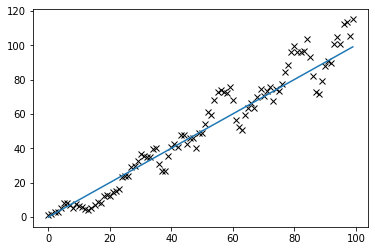

In [3]:
# Rasgele yuruyus - ortalama
from numpy import *
from pylab import *
def rasgele(jbasla):
    ia=211;ib=1663;ic=7875
    jbasla=(jbasla*ia+ib)%ic
    return float(jbasla)/float(ic), jbasla
jbasla=788711;nadim=100;nyuruyen=200
adim = zeros(nadim)
yerortalama = zeros(nadim)
for j in range(nadim):
    yerortalama[j]=0.0
for i in range(nyuruyen):
    yer=0.0
    for j in range(nadim):
        xd,jbasla=rasgele(jbasla)
        if xd<0.5:
            yer=yer-1
        else:
            yer=yer+1
        yerortalama[j]=yerortalama[j]+yer**2
for j in range(nadim):
    yerortalama[j]=yerortalama[j]/nyuruyen
    adim[j]=j
plot(adim,yerortalama,"kx")
plot(adim,adim)
show()


In [ ]:
# Monte-Carlo integrali
def rasgele(jbasla):
    ia=211;ib=1663;ic=7875
    jbasla=(jbasla*ia+ib)%ic
    return float(jbasla)/float(ic), jbasla
def f(x):
    return x**3
jbasla=113
nmax=1000
for i in range(10):
    toplam=0.0
    for j in range(nmax):
        x,jbasla=rasgele(jbasla)
        toplam=toplam+f(x)
    aintegral=toplam/nmax
    print (nmax,  "%.8f" % aintegral)
    nmax=nmax+1000


In [ ]:
# Monte-Carlo integrali
def rasgele(jbasla):
    ia=211;ib=1663;ic=7875
    jbasla=(jbasla*ia+ib)%ic
    return float(jbasla)/float(ic), jbasla
def f(x):
    return x**3
jbasla=113
nmax=1000
for i in range(10):
    toplam=0.0
    for j in range(nmax):
        x,jbasla=rasgele(jbasla)
        toplam=toplam+f(x)
    aintegral=toplam/nmax
    print(nmax,  "%.8f" % aintegral)
    nmax=nmax+1000


In [ ]:
# Ising modeli
from numpy import *
from pylab import *
def rasgele(jbasla):
    ia=211;ib=1663;ic=7875
    jbasla=(jbasla*ia+ib)%ic
    return float(jbasla)/float(ic), jbasla
def c(t,komsu):
    t=float(it+1)/4
    e4=exp(-4./t)
    e8=e4**2
    if komsu==0:
        c=0.0
    if komsu==2:
        c=e4
    if komsu==4:
        c=e8
    if komsu==-2:
        c=1./e4
    if komsu==-4:
        c=1./e8
    return c
jbasla=345;L=32;mcarlo=1000
L2=L**2
print "T ", "M ortalama", "E ortalama"
#Sicaklik dongusu. 
for it in range(20):
    t=float(it)/4
#Baslangicta rasgele bir konfigurasyon olustur. E ve M yi hesapla.
    m=0
    spin = zeros((L,L))
    for i in range(L):
        for j in range(L):
            xras,jbasla=rasgele(jbasla)
            if xras<0.5:
                spin[i,j]=1
            else:
                spin[i,j]=-1
    enerji=0
    for j in range(L):
        if j==L-1:
            iust=1
        else:
            iust=j+1
        for i in range(L):
            if i==L-1:
                isag=1
            else:
                isag=i+1
            enerji=enerji-spin[i,j]*(spin[i,iust]+spin[isag,j])
# Monte Carlo dongusu. Spinleri alt-ust et. Enerjisini kiyasla.
    m_kumula=0
    e_kumula=0
    for imc in range(mcarlo):
        for k in range(L2):
            xras,jbasla=rasgele(jbasla)
            i=int(L*xras)
            xras,jbasla=rasgele(jbasla)
            j=int(L*xras)
            if i==0:
                isol=spin[L-1,j]
            else:
                isol=spin[i-1,j]
            if i==L-1:
                isag=spin[0,j]
            else:
                isag=spin[i+1,j]
            if j==0:
                ialt=spin[i,L-1]
            else:
                ialt=spin[i,j-1]
            if j==L-1:
                iust=spin[i,0]
            else:
                iust=spin[i,j+1]
            komsu=isol+isag+iust+ialt
            delta_E=spin[i,j]*komsu
            xras,jbasla=rasgele(jbasla)
            if delta_E<=0.0:
                spin[i,j]=-spin[i,j]
                m=m+2*spin[i,j]
                enerji=enerji-2*delta_E
            elif xras<c(t,komsu):
                spin[i,j]=-spin[i,j]
                m=m+2*spin[i,j]
                enerji=enerji-2*delta_E
        e_kumula=e_kumula+enerji
        m_kumula=m_kumula+m
    sabit=1.0/float(L2*mcarlo)
    e_orta=e_kumula*sabit
    m_orta=m_kumula*sabit
    print (t, "%.8f" % e_orta, "%.8f" % m_orta)
    plot(t,m_orta,"ko")
show()


T  M ortalama E ortalama
0.0 2.09761328 0.99332422
0.25 1.96090234 0.99333984
0.5 1.98885938 0.98225586
0.75 2.04964062 1.00815039
1.0 1.94561719 1.00538281
1.25 1.90286328 0.97591016
1.5 1.90892578 0.91530859
1.75 1.69983203 0.87243359
2.0 1.38872266 0.78653906
2.25 1.30394141 0.70431250
2.5 1.19262891 0.66055469
2.75 1.01638281 0.58112500
3.0 1.00593750 0.53037500
3.25 0.85148047 0.50181836
3.5 0.78744141 0.46783398
3.75 0.81340625 0.44127734
4.0 0.74585156 0.42551953
4.25 0.49275781 0.33957227
4.5 0.54541797 0.29355664
4.75 0.38769531 0.20844141


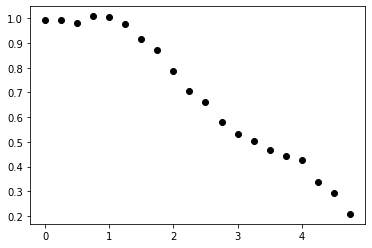

In [2]:
#Ising
#from numpy import *
import numpy as np
from pylab import *
from math import *
def rasgele(jbasla):
    ia=211;ib=1663;ic=7875
    jbasla=(jbasla*ia+ib)%ic
    return float(jbasla)/float(ic), jbasla
def c(t,komsu):
    t=float(it+1)/4
    e4=exp(-4./t)
    e8=e4**2
    if komsu==0:
        c=0.0
    if komsu==2:
        c=e4
    if komsu==4:
        c=e8
    if komsu==-2:
        c=1./e4
    if komsu==-4:
        c=1./e8
    return c

jbasla=345;L=32;mcarlo=1000
L2=L**2
print("T ", "M ortalama", "E ortalama")
#Sicaklik dongusu. 
for it in range(20):
    t=float(it)/4

#Baslangicta rasgele bir konfigurasyon olustur. E ve M yi hesapla.
    m=0
    spin = np.zeros((L,L))
#    spin = empty(L, L)
#    spin = numpy.empty((L, L))
    for i in range(L):
        for j in range(L):
            xras,jbasla=rasgele(jbasla)
            if xras<0.5:
                spin[i,j]=1
            else:
                spin[i,j]=-1
    enerji=0
    for j in range(L):
        if j==L-1:
            iust=1
        else:
            iust=j+1
        for i in range(L):
            if i==L-1:
                isag=1
            else:
                isag=i+1
            enerji=enerji-spin[i,j]*(spin[i,iust]+spin[isag,j])

# Monte Carlo dongusu. Spinleri alt-ust et. Enerjisini kiyasla.
#Calisiyo ama hala matris boyutlarinda hata olabilir (isol,isag,...)
    m_kumula=0
    e_kumula=0
    for imc in range(mcarlo):
        for k in range(L2):
            xras,jbasla=rasgele(jbasla)
            i=int(L*xras)
            xras,jbasla=rasgele(jbasla)
            j=int(L*xras)
            if i==0:
                isol=spin[L-1,j]
            else:
                isol=spin[i-1,j]
            if i==L-1:
                isag=spin[0,j]
            else:
                isag=spin[i+1,j]
            if j==0:
                ialt=spin[i,L-1]
            else:
                ialt=spin[i,j-1]
            if j==L-1:
                iust=spin[i,0]
            else:
                iust=spin[i,j+1]
            komsu=isol+isag+iust+ialt
            delta_E=spin[i,j]*komsu
            xras,jbasla=rasgele(jbasla)
            if delta_E<=0.0:
                spin[i,j]=-spin[i,j]
                m=m+2*spin[i,j]
                enerji=enerji-2*delta_E
            elif xras<c(t,komsu):
                spin[i,j]=-spin[i,j]
                m=m+2*spin[i,j]
                enerji=enerji-2*delta_E
        e_kumula=e_kumula+enerji
        m_kumula=m_kumula+m

    sabit=1.0/float(L2*mcarlo)
    e_orta=e_kumula*sabit
    m_orta=m_kumula*sabit
    print (t, "%.8f" % e_orta, "%.8f" % m_orta)
    plot(t,m_orta,"ko")
show()


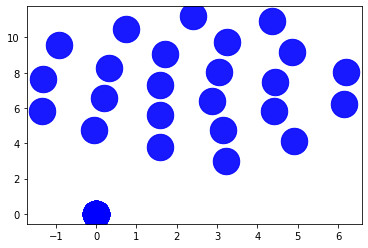

In [1]:
# Molekuler Dinamik
from numpy import *
from pylab import *
def rasgele(jbasla):
    ia=211;ib=1663;ic=7875
    jbasla=(jbasla*ia+ib)%ic
    return float(jbasla)/float(ic), jbasla
def f(r):
    global rz
    return (-1.0+(rz/r)**7)/r**2
akenar=10.0;alfa=2.0;natom=24;jbasla=1881
rz=2.0
x = zeros(60);y = zeros(60)
for i in range(natom):
    xd,jbasla=rasgele(jbasla)
    x[i]=akenar*xd
    yd,jbasla=rasgele(jbasla)
    y[i]=akenar*yd
for k in range(1000):
    for i in range(natom):
        fxi=0.0
        fyi=0.0
        for j in range(natom):
            if j!=i:
                rij=sqrt((x[j]-x[i])**2+(y[j]-y[i])**2)
                fxi=fxi+f(rij)*(x[i]-x[j])/rij
                fyi=fyi+f(rij)*(y[i]-y[j])/rij
        dx=alfa*fxi
        dy=alfa*fyi
        if dx<(-0.01*akenar): dx=-0.01*akenar
        if dy<(-0.01*akenar): dy=-0.01*akenar
        if dx>(0.01*akenar):  dx=0.01*akenar
        if dy>(0.01*akenar):  dy=0.01*akenar
        x[i]=x[i]+dx
        y[i]=y[i]+dy
scatter(x,y,s=700,alpha=.9,color="b")
show()
